# Modelado: ¿quién gana sabiendo la composición de los equipos?

Ciencia de Datos · UTN FRM · 2026 · Entrega 3

Este notebook toma el dataset de partidas de Deadlock que arma el DAG `deadlock_ingest` y lo convierte en el modelo que va a usar la aplicación de la Entrega 4. Sigue el orden del instructivo: primero el **planteo** (qué se predice, con qué métrica, contra qué piso y cómo se parten los datos), después la **comparación** de familias de modelos por validación cruzada, el **ajuste** del elegido, **lo que probamos y no anduvo**, y al final el **modelo final leído** sobre el test, que se mira una sola vez.

Se corre de arriba hacia abajo. La semilla se define una vez y se pasa a todo lo que la acepta, y todo lo que se le hace a los datos está adentro de un `Pipeline`. Los números de la prosa salen de celdas ejecutadas, no están tipeados.

## 0. Qué cambió desde la Entrega 2

- **Los datos.** En la Entrega 2 había un solo corte (16/09, 30.000 partidas). Acá se juntan **varios cortes en el tiempo**, cada uno con sus propias estadísticas de los 14 días anteriores, porque el modelo se va a usar sobre partidas futuras y la validación tiene que imitar eso.
- **Las columnas.** Son las mismas 66 de la Entrega 2. Las decisiones de la tabla de candidatas (H3: redundantes; H4: `average_badge_diff`) se vuelven a medir acá, ahora con un modelo, en la sección 6.
- **Lo que nos marcó el docente en la Entrega 2:** *PENDIENTE — completar con la devolución y cómo se resolvió.*

In [1]:
# Las herramientas de todo el notebook
import re, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")

SEMILLA = 42
np.random.seed(SEMILLA)

VERDE_AZUL, TERRACOTA, GRIS = "#009086", "#B5402C", "#7a7974"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 80)


def c(x, d=3):
    '''Número con coma decimal, para la prosa en castellano.'''
    return f"{x:.{d}f}".replace(".", ",")


def miles(x):
    '''Entero con separador de miles (el § se vuelve punto recién en leer).'''
    return f"{x:,}".replace(",", "§")


def leer(texto):
    '''Muestra prosa en castellano: coma decimal fuera de los `códigos`, punto de miles donde hay §.'''
    partes = texto.split("`")
    for i in range(0, len(partes), 2):
        partes[i] = re.sub(r"(?<=\d)\.(?=\d)", ",", partes[i])
    display(Markdown("`".join(partes).replace("§", ".")))

## 1. Los datos: un corte por carpeta

El DAG deja, por cada fecha de corte `T`, una carpeta `silver/corte=T/features.parquet` con las 73 columnas. Cada corte tiene **sus propias** estadísticas de héroes (las de los 14 días anteriores a `T`) y sus propias partidas (las de los días posteriores a `T`). El notebook lee todos los cortes que haya: si se agrega uno, entra solo.

In [2]:
# ¿Qué cortes hay, cuántas partidas tiene cada uno y qué fechas cubren?
RAIZ = Path.cwd() if (Path.cwd() / "include").exists() else Path.cwd().parent
PLATA = RAIZ / "include" / "output" / "silver"
sys.path.insert(0, str(RAIZ / "include"))
from deadlock import schema

partes = []
for carpeta in sorted(PLATA.glob("corte=*")):
    t = pd.read_parquet(carpeta / "features.parquet")
    t["corte"] = carpeta.name.split("=")[1]
    partes.append(t)
df = pd.concat(partes, ignore_index=True)
assert df["match_id"].is_unique, "una partida aparece en dos cortes"

cortes = df.groupby("corte").agg(partidas=("match_id", "size"), primera=("match_date", "min"),
                                 ultima=("match_date", "max"), gana_A=("winner", lambda s: s.eq("A").mean()))
cortes.round(3)

,partidas,primera,ultima,gana_A
corte,,,,
2026-08-20,10000,2026-08-20,2026-08-20,0.500
2026-08-27,10000,2026-08-27,2026-08-27,0.497
2026-09-03,10000,2026-09-03,2026-09-03,0.515
2026-09-10,10000,2026-09-10,2026-09-10,0.515
2026-09-20,10000,2026-09-20,2026-09-20,0.502


In [3]:
# ¿Alguna partida es anterior a su propio corte? Si lo fuera, sus estadísticas la incluirían (fuga)
anteriores = {corte: int((pd.to_datetime(t["match_date"]) < pd.Timestamp(corte)).sum()) for corte, t in df.groupby("corte")}
assert sum(anteriores.values()) == 0, "hay partidas anteriores al corte: las ventanas se pisan"
pd.Series(anteriores, name="partidas anteriores al corte")

2026-08-20    0
2026-08-27    0
2026-09-03    0
2026-09-10    0
2026-09-20    0
Name: partidas anteriores al corte, dtype: int64

In [4]:
leer(f'''Hay **{len(cortes)} cortes** y **{miles(len(df))} partidas** en total. Ninguna partida es anterior a la fecha de su corte, así que ninguna fila está dentro de la ventana de estadísticas con la que se calcularon sus propias columnas: es el chequeo anti-fuga de la Entrega 2, ahora corte por corte. En todos los cortes el equipo A gana entre el {cortes['gana_A'].min():.1%} y el {cortes['gana_A'].max():.1%} de las veces.''')

Hay **5 cortes** y **50.000 partidas** en total. Ninguna partida es anterior a la fecha de su corte, así que ninguna fila está dentro de la ventana de estadísticas con la que se calcularon sus propias columnas: es el chequeo anti-fuga de la Entrega 2, ahora corte por corte. En todos los cortes el equipo A gana entre el 49,7% y el 51,5% de las veces.

## 2. El planteo

### 2.1 Qué se predice y qué no puede estar

El objetivo es `winner`: **1 si gana el equipo A, 0 si gana el B**. A es `Team0` en la API, una asignación arbitraria respecto de la habilidad.

Las columnas de entrada son las 66 de composición y ventajas (`schema.FEATURE_COLUMNS`), más `average_badge_diff`, que entra a `X` **sólo para poder medirla** en la sección 6 (la Entrega 2 la descartó por inútil y dejó abierta la pregunta de si aporta junto con la composición). Quedan afuera los identificadores (`match_id`, `match_date`, `corte`), las constantes (`game_mode`, `match_mode`) y `average_badge`, que se usa para leer dónde se equivoca el modelo, no para predecir.

Las 66 columnas ya vienen calculadas por el DAG. Eso **no** es preparar los datos afuera del pipeline: cada ventaja se calcula con las estadísticas de los 14 días anteriores al corte, no con las filas del dataset, así que no hay nada de las partidas de validación ni de test adentro de ellas. Es una tabla de consulta externa, como un catálogo, y el chequeo de arriba lo garantiza.

In [5]:
y = df["winner"].eq("A").astype(int)
COLUMNAS = schema.FEATURE_COLUMNS + ["average_badge_diff"]
X = df[COLUMNAS]
pd.Series({"filas": len(X), "columnas en X": X.shape[1], "proporción en que gana A": round(y.mean(), 4)}, dtype=object)

filas                        50000
columnas en X                   67
proporción en que gana A    0.5058
dtype: object

### 2.2 La métrica, declarada antes de elegir

**ROC AUC**, con la accuracy informada al lado en todas las tablas.

- **Qué error es más caro.** Ninguno: A y B son etiquetas arbitrarias, así que decir "gana A" cuando gana B es el mismo error que el inverso, espejado. Con clases 50/50 no hay una clase chica que la accuracy esconda; la accuracy no está mal, y por eso se informa siempre.
- **Por qué AUC y no accuracy como principal.** El modelo se va a usar en la aplicación para mostrar **una probabilidad** ("A tiene 61 % de chances"), no sólo un lado. El AUC mide si el modelo *ordena* bien las partidas —si a las que gana A les da más probabilidad que a las que pierde— usando la probabilidad entera. La accuracy sólo mira de qué lado del 0,5 cayó cada una: una partida en 0,51 y otra en 0,80 cuentan igual.
- **Cómo se lee.** El AUC es la probabilidad de que, tomando al azar una partida que ganó A y una que perdió, el modelo le haya dado más probabilidad a la que ganó. 0,5 es una moneda; 1 es ordenar perfecto.
- **Lo que el AUC no mide** es si un 0,61 significa de verdad 61 de cada 100. Eso es la calibración, y se mira en la sección 7 porque es lo que va a mostrar la aplicación.

In [6]:
ESCALA = {"auc": "roc_auc", "acc": "accuracy"}

### 2.3 La partición imita el uso

El modelo se usa sobre **partidas que todavía no se jugaron**, con las estadísticas de los 14 días previos a ese momento. Eso define cómo se parten los datos:

- **El test es el corte más reciente, entero.** Ninguna partida de ese corte se usa para entrenar ni para elegir nada. Mide exactamente el uso: un modelo entrenado con semanas anteriores, aplicado a una que no vio.
- **La validación es walk-forward con ventana deslizante** (`VentanaDeslizante`, con `m = 1`): en cada paso se entrena **sólo con los últimos `m` cortes**, no con todo lo anterior, y se valida con el corte siguiente. Siempre se valida hacia adelante en el tiempo, y lo viejo se va soltando: el *meta* cambia de una semana a otra, y lo que se aprendió hace un mes puede decir algo que ya no es cierto. Con `m = 1`:

```
              20/08  27/08  03/09  10/09  │ 20/09
paso 1:         E      V      ·      ·    │
paso 2:         ·      E      V      ·    │
paso 3:         ·      ·      E      V    │
final:          ·      ·      ·      E    │  TEST
```

- **El modelo final es el paso siguiente**: se entrena con los últimos `m` cortes de entrenamiento y se aplica al test, igual que se va a usar en la aplicación. Las partidas de un mismo corte comparten las estadísticas con las que se calcularon y el meta de esos días, por eso nunca se reparten entre entrenamiento y validación; la sección 4.3 mide cuánto cambiaría el número si se repartieran al azar.


In [7]:
CORTE_TEST = df["corte"].max()
es_test = df["corte"].eq(CORTE_TEST)
VENTANA = 1   # m: cuántos cortes hacia atrás ve cada entrenamiento

X_train, y_train, g_train = X[~es_test], y[~es_test], df.loc[~es_test, "corte"]
X_test, y_test = X[es_test], y[es_test]


class VentanaDeslizante:
    '''Walk-forward con ventana deslizante: entrena con los m cortes anteriores y valida con el siguiente.'''

    def __init__(self, m=1):
        self.m = m

    def split(self, X, y=None, groups=None):
        g = np.asarray(groups)
        orden = np.sort(np.unique(g))   # las fechas 'AAAA-MM-DD' ordenan igual como texto que en el tiempo
        for i in range(self.m, len(orden)):
            yield np.flatnonzero(np.isin(g, orden[i - self.m:i])), np.flatnonzero(g == orden[i])

    def get_n_splits(self, X=None, y=None, groups=None):
        return len(np.unique(groups)) - self.m


cv = VentanaDeslizante(VENTANA)

pd.DataFrame([{"paso": i + 1, "entrena con": ", ".join(sorted(g_train.iloc[e].unique())),
               "valida con": ", ".join(sorted(g_train.iloc[v].unique())), "filas que entrena": len(e), "filas que valida": len(v)}
              for i, (e, v) in enumerate(cv.split(X_train, y_train, g_train))]).set_index("paso")


,entrena con,valida con,filas que entrena,filas que valida
paso,,,,
1,2026-08-20,2026-08-27,10000,10000
2,2026-08-27,2026-09-03,10000,10000
3,2026-09-03,2026-09-10,10000,10000


In [8]:
pasos = cv.get_n_splits(groups=g_train)
filas_por_paso = len(next(cv.split(X_train, y_train, g_train))[0])
leer(f'''Entrenamiento: **{miles(len(X_train))} partidas** de {g_train.nunique()} cortes. Test: **{miles(len(X_test))} partidas** del corte `{CORTE_TEST}`, que no se mira hasta la sección 7. El walk-forward tiene **{pasos} pasos**: en cada uno se entrena con {VENTANA} corte{'s' if VENTANA > 1 else ''} ({miles(filas_por_paso)} partidas) y se valida con el que sigue. El desvío de cada tabla se calcula sobre esos {pasos} números{' — son pocos; cada corte nuevo que se agregue al DAG suma un paso' if pasos < 4 else ''}.''')


Entrenamiento: **40.000 partidas** de 4 cortes. Test: **10.000 partidas** del corte `2026-09-20`, que no se mira hasta la sección 7. El walk-forward tiene **3 pasos**: en cada uno se entrena con 1 corte (10.000 partidas) y se valida con el que sigue. El desvío de cada tabla se calcula sobre esos 3 números — son pocos; cada corte nuevo que se agregue al DAG suma un paso.

## 3. El pipeline

Cada modelo es un `Pipeline` de tres pasos: **elegir** qué bloques de columnas usa, **escalar** y **clasificar**. Elegir columnas es un paso propio (`ElegirColumnas`), con la receta de la Práctica 1, para que el conjunto de columnas sea un hiperparámetro más y la búsqueda de la sección 5 pueda moverlo.

Las 66 columnas se agrupan en bloques con significado de juego:

In [9]:
from sklearn.base import BaseEstimator, TransformerMixin, clone

BLOQUES = {
    "fuerza_media":    ["hero_winrate_adv_mean"],                                          # fuerza individual promedio, A − B
    "fuerza_resto":    ["hero_winrate_adv_min", "hero_winrate_adv_max", "hero_winrate_adv_std"],
    "counter_winrate": [k for k in schema.COUNTER if k.startswith("counter_winrate")],     # cruces A×B, winrate
    "counter_otras":   [k for k in schema.COUNTER if not k.startswith("counter_winrate")], # cruces: kills, muertes, asistencias, souls
    "synergy":         schema.SYNERGY,                                                     # parejas internas
    "composicion":     schema.COMPOSICION,                                                 # un héroe por columna, ±1
    "rango":           ["average_badge_diff"],                                             # sólo para la sección 6
}
VENTAJAS = ("fuerza_media", "fuerza_resto", "counter_winrate", "counter_otras", "synergy")
TODAS = VENTAJAS + ("composicion",)
NOMBRE_BLOQUES = {("fuerza_media",): "una columna", VENTAJAS: "ventajas (28)", ("composicion",): "composición (38)", TODAS: "todas (66)"}

assert sum(len(BLOQUES[b]) for b in TODAS) == len(schema.FEATURE_COLUMNS)
pd.Series({b: len(cols) for b, cols in BLOQUES.items()}, name="columnas")

fuerza_media        1
fuerza_resto        3
counter_winrate     4
counter_otras      16
synergy             4
composicion        38
rango               1
Name: columnas, dtype: int64

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


class ElegirColumnas(BaseEstimator, TransformerMixin):
    '''Se queda con las columnas de los bloques pedidos. Es un paso del pipeline para que los bloques sean un hiperparámetro.'''

    def __init__(self, bloques=TODAS):
        self.bloques = bloques

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns)
        self.columnas_ = list(dict.fromkeys(col for b in self.bloques for col in BLOQUES[b]))   # sin repetir si dos bloques comparten una
        return self

    def transform(self, X):
        return X[self.columnas_]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columnas_)


def armar(modelo, bloques=TODAS):
    '''Elegir columnas, escalar y clasificar: la receta de todos los modelos del notebook.'''
    return Pipeline([("elegir", ElegirColumnas(bloques)), ("escalar", StandardScaler()), ("modelo", modelo)])


armar(None)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('elegir', ...), ('escalar', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,bloques,"('fuerza_media', ...)"
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Escalar importa para la logística: la multa de la regularización es sobre el tamaño de los pesos, y las ventajas de souls están en miles mientras las de winrate están en centésimas (Entrega 2, sección 2). A los árboles no les cambia nada, pero se deja el mismo paso para que todos los modelos reciban exactamente lo mismo.

In [11]:
from sklearn.model_selection import cross_validate


def medir(pipe, cv=cv, groups=g_train):
    '''AUC y accuracy en los pasos del walk-forward sobre el entrenamiento: media, desvío y la brecha con train.'''
    r = cross_validate(pipe, X_train, y_train, groups=groups, cv=cv, scoring=ESCALA,
                       return_train_score=True, n_jobs=-1)
    return {"AUC": r["test_auc"].mean(), "desvío AUC": r["test_auc"].std(),
            "accuracy": r["test_acc"].mean(), "desvío acc": r["test_acc"].std(),
            "AUC en train": r["train_auc"].mean(), "segundos por turno": r["fit_time"].mean()}

## 4. La comparación

### 4.1 El piso y la línea base de dominio

Dos referencias, medidas con la misma validación que todo lo demás:

- **El piso**: un `DummyClassifier` que contesta siempre la clase más frecuente y no mira ninguna columna.
- **La regla de una columna**: una logística que sólo ve `hero_winrate_adv_mean`, la fuerza individual promedio de los héroes de A menos la de B. Es la "regla de un umbral" de H1 en la Entrega 2. Es la vara de verdad: un modelo que no le gana a una columna no justifica las otras 65.

### 4.2 Cuatro familias sobre las mismas columnas

La logística primero, porque es la referencia contra la que se justifica cualquier otra cosa; después un árbol, un bosque y un boosting. Las cuatro reciben las mismas 66 columnas y se miden con la misma validación. Acá van con sus valores por defecto; la sección 5 ajusta las cuatro.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

modelos = {
    "piso (dummy)":        armar(DummyClassifier(strategy="most_frequent"), ("fuerza_media",)),
    "regla: una columna":  armar(LogisticRegression(), ("fuerza_media",)),
    "regresión logística": armar(LogisticRegression(max_iter=5000)),
    "árbol de decisión":   armar(DecisionTreeClassifier(random_state=SEMILLA)),
    "random forest":       armar(RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=SEMILLA)),
    "gradient boosting":   armar(HistGradientBoostingClassifier(random_state=SEMILLA)),
}

comparacion = pd.DataFrame({nombre: medir(p) for nombre, p in modelos.items()}).T
comparacion.round(3)

,AUC,desvío AUC,accuracy,desvío acc,AUC en train,segundos por turno
piso (dummy),0.500,0.000,0.501,0.012,0.500,0.067
regla: una columna,0.613,0.002,0.580,0.001,0.610,0.057
regresión logística,0.607,0.003,0.576,0.006,0.626,0.106
árbol de decisión,0.515,0.002,0.516,0.002,1.000,0.445
random forest,0.594,0.002,0.567,0.005,1.000,5.873
gradient boosting,0.582,0.003,0.560,0.005,0.945,0.707


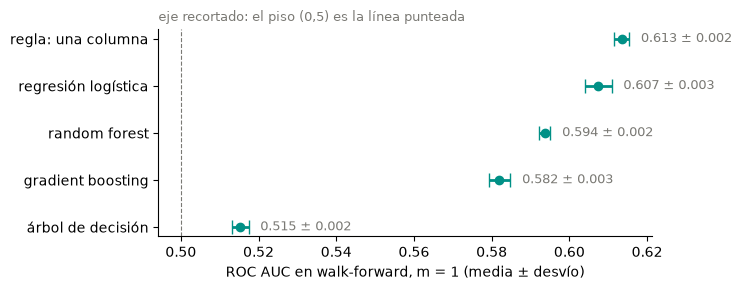

In [13]:
# La misma tabla, dibujada: el punto es la media y la barra, un desvío a cada lado
tabla = comparacion.drop(index="piso (dummy)").sort_values("AUC")
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.errorbar(tabla["AUC"], tabla.index, xerr=tabla["desvío AUC"], fmt="o", color=VERDE_AZUL, ecolor=VERDE_AZUL,
            elinewidth=2, capsize=5)
for nombre, fila in tabla.iterrows():
    ax.text(fila["AUC"] + fila["desvío AUC"] + 0.003, nombre, f"{fila['AUC']:.3f} ± {fila['desvío AUC']:.3f}",
            va="center", fontsize=9, color=GRIS)
ax.axvline(0.5, color=GRIS, lw=0.8, ls="--")
ax.set_xlabel("ROC AUC en walk-forward, m = 1 (media ± desvío)")
ax.set_title("eje recortado: el piso (0,5) es la línea punteada", fontsize=9, color=GRIS, loc="left")
plt.tight_layout()
plt.show()

In [14]:
regla, logistica = comparacion.loc["regla: una columna"], comparacion.loc["regresión logística"]
mejor_comp = comparacion.drop(index=["piso (dummy)", "regla: una columna"])["AUC"].idxmax()
brechas = (comparacion["AUC en train"] - comparacion["AUC"]).drop(index="piso (dummy)")
leer(f'''**Lectura.** El piso da AUC {c(comparacion.loc['piso (dummy)', 'AUC'])} y accuracy {c(comparacion.loc['piso (dummy)', 'accuracy'])}. La regla de una sola columna llega a AUC **{c(regla['AUC'])}** (± {c(regla['desvío AUC'])}) y accuracy **{c(regla['accuracy'])}**: hay señal, y una sola columna la captura. La mejor de las cuatro familias con valores por defecto es `{mejor_comp}`, con AUC {c(comparacion.loc[mejor_comp, 'AUC'])} (± {c(comparacion.loc[mejor_comp, 'desvío AUC'])}), {'por encima' if comparacion.loc[mejor_comp, 'AUC'] > regla['AUC'] else 'por debajo'} de la regla por {c(abs(comparacion.loc[mejor_comp, 'AUC'] - regla['AUC']))}.

La columna de train muestra el sobreajuste: el árbol sin límite llega a {c(comparacion.loc['árbol de decisión', 'AUC en train'])} en train y {c(comparacion.loc['árbol de decisión', 'AUC'])} en validación (brecha {c(brechas['árbol de decisión'])}), y el bosque a {c(comparacion.loc['random forest', 'AUC en train'])}. Memorizan las partidas de entrenamiento. La logística con las 66 columnas también tiene brecha ({c(brechas['regresión logística'])}), de otra naturaleza: no memoriza partidas, pero aprende un peso por héroe que vale para el momento del juego de su corte y no para el otro. La regla de una columna no tiene brecha ({c(brechas['regla: una columna'])}): lo que acierta en train lo acierta en un corte que no vio.''')

**Lectura.** El piso da AUC 0,500 y accuracy 0,501. La regla de una sola columna llega a AUC **0,613** (± 0,002) y accuracy **0,580**: hay señal, y una sola columna la captura. La mejor de las cuatro familias con valores por defecto es `regresión logística`, con AUC 0,607 (± 0,003), por debajo de la regla por 0,006.

La columna de train muestra el sobreajuste: el árbol sin límite llega a 1,000 en train y 0,515 en validación (brecha 0,485), y el bosque a 1,000. Memorizan las partidas de entrenamiento. La logística con las 66 columnas también tiene brecha (0,019), de otra naturaleza: no memoriza partidas, pero aprende un peso por héroe que vale para el momento del juego de su corte y no para el otro. La regla de una columna no tiene brecha (-0,003): lo que acierta en train lo acierta en un corte que no vio.

### 4.3 Qué le pasaría al número si los pedazos se armaran al azar

La misma comparación, con una validación cruzada estratificada al azar (`StratifiedKFold`) sobre los cortes de entrenamiento juntos, en lugar del walk-forward. Si las partidas de un mismo corte fueran independientes del resto, los dos números tendrían que coincidir. La comparación no es pura: al azar cada turno entrena con el 80 % de todos los cortes, no con uno solo, así que la diferencia mezcla ver el mismo meta de los dos lados con entrenar con más partidas.


In [15]:
from sklearn.model_selection import StratifiedKFold

al_azar = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
validaciones = pd.DataFrame({nombre: {"walk-forward (m = 1)": comparacion.loc[nombre, "AUC"],
                                      "al azar (StratifiedKFold)": medir(modelos[nombre], cv=al_azar)["AUC"]}
                             for nombre in ["regla: una columna", "regresión logística", "gradient boosting"]}).T
validaciones["diferencia"] = validaciones["al azar (StratifiedKFold)"] - validaciones["walk-forward (m = 1)"]
validaciones.round(3)

,walk-forward (m = 1),al azar (StratifiedKFold),diferencia
regla: una columna,0.613,0.612,-0.002
regresión logística,0.607,0.617,0.010
gradient boosting,0.582,0.608,0.026


In [16]:
d = validaciones["diferencia"]
leer(f'''Al azar, la regla de una columna cambia {c(d['regla: una columna'])}, y la logística con las 66 columnas {c(d['regresión logística'])}; el boosting, {c(d['gradient boosting'])}. La regla casi no depende de cómo se parta: usa una columna que se recalcula en cada corte con las estadísticas de ese momento. Los modelos que aprenden un peso por héroe sí dependen: con la partición al azar ven el meta de cada corte de los dos lados, y {'el número les sube' if d.drop('regla: una columna').max() > 0 else 'aun así el número no les sube, lo que dice que con estos cortes el meta cambió poco'}. Esa diferencia es la que el walk-forward no deja pasar.''')

Al azar, la regla de una columna cambia -0,002, y la logística con las 66 columnas 0,010; el boosting, 0,026. La regla casi no depende de cómo se parta: usa una columna que se recalcula en cada corte con las estadísticas de ese momento. Los modelos que aprenden un peso por héroe sí dependen: con la partición al azar ven el meta de cada corte de los dos lados, y el número les sube. Esa diferencia es la que el walk-forward no deja pasar.

## 5. El ajuste

Se ajustan las cuatro familias, no sólo la que va ganando: es la única forma de saber si el orden de la sección 4 es de las familias o de los valores por defecto. Cada grilla mueve los hiperparámetros que controlan la complejidad de su familia; la de la logística mueve además **qué bloques de columnas** usa. Todo con el mismo walk-forward, eligiendo por AUC.

In [17]:
from sklearn.model_selection import GridSearchCV

grillas = {
    "regresión logística": (armar(LogisticRegression(max_iter=5000)),
                            {"elegir__bloques": [("fuerza_media",), VENTAJAS, ("composicion",), TODAS],
                             "modelo__C": [0.001, 0.01, 0.1, 1, 10]}),
    "árbol de decisión":   (armar(DecisionTreeClassifier(random_state=SEMILLA)),
                            {"modelo__max_depth": [3, 6, 10], "modelo__min_samples_leaf": [20, 100, 500]}),
    "random forest":       (armar(RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=SEMILLA)),
                            {"modelo__max_depth": [6, 12, None], "modelo__min_samples_leaf": [20, 100]}),
    "gradient boosting":   (armar(HistGradientBoostingClassifier(random_state=SEMILLA)),
                            {"modelo__learning_rate": [0.03, 0.1], "modelo__max_leaf_nodes": [7, 31],
                             "modelo__max_iter": [100, 300]}),
}

busquedas = {nombre: GridSearchCV(p, g, cv=cv, scoring=ESCALA, refit="auc", n_jobs=-1, return_train_score=True)
                     .fit(X_train, y_train, groups=g_train)
             for nombre, (p, g) in grillas.items()}

pd.DataFrame({nombre: {"AUC por defecto (4.2)": comparacion.loc[nombre, "AUC"],
                       "AUC mejor de la grilla": b.best_score_,
                       "desvío": b.cv_results_["std_test_auc"][b.best_index_],
                       "accuracy de ese": b.cv_results_["mean_test_acc"][b.best_index_],
                       "combinaciones": len(b.cv_results_["params"])}
              for nombre, b in busquedas.items()}).T.round(3)

,AUC por defecto (4.2),AUC mejor de la grilla,desvío,accuracy de ese,combinaciones
regresión logística,0.607,0.614,0.002,0.580,20.0
árbol de decisión,0.515,0.606,0.000,0.579,9.0
random forest,0.594,0.611,0.003,0.580,6.0
gradient boosting,0.582,0.611,0.000,0.580,8.0


In [18]:
# Con qué hiperparámetros llegó cada familia a su mejor
def legible(v):
    return NOMBRE_BLOQUES.get(v, v) if isinstance(v, tuple) else v

pd.DataFrame({nombre: {k.split("__")[-1]: legible(v) for k, v in b.best_params_.items()}
              for nombre, b in busquedas.items()}).T.fillna("")

,bloques,C,max_depth,min_samples_leaf,learning_rate,max_iter,max_leaf_nodes
regresión logística,composición (38),0.1,,,,,
árbol de decisión,,,3.0,500.0,,,
random forest,,,6.0,100.0,,,
gradient boosting,,,,,0.03,100.0,7.0


### 5.1 La tabla entera de la logística, no sólo el ganador

In [19]:
def tabla_de(busqueda):
    '''cv_results_ reducido a lo que se lee: hiperparámetros, AUC y accuracy en validación, AUC en train.'''
    r = pd.DataFrame(busqueda.cv_results_)
    params = [k for k in r.columns if k.startswith("param_")]
    t = r[params + ["mean_test_auc", "std_test_auc", "mean_test_acc", "mean_train_auc"]].copy()
    for p in params:
        t[p] = t[p].map(legible)
    return (t.rename(columns=lambda k: k.split("__")[-1].replace("param_", ""))
             .sort_values("mean_test_auc", ascending=False))

tabla_logistica = tabla_de(busquedas["regresión logística"])
tabla_logistica.round(4)

,bloques,C,mean_test_auc,std_test_auc,mean_test_acc,mean_train_auc
12,composición (38),0.100,0.6140,0.0024,0.5795,0.6212
14,composición (38),10.000,0.6140,0.0024,0.5799,0.6212
13,composición (38),1.000,0.6140,0.0024,0.5798,0.6212
11,composición (38),0.010,0.6139,0.0025,0.5796,0.6212
3,una columna,1.000,0.6135,0.0019,0.5798,0.6101
2,una columna,0.100,0.6135,0.0019,0.5799,0.6101
1,una columna,0.010,0.6135,0.0019,0.5799,0.6101
0,una columna,0.001,0.6135,0.0019,0.5815,0.6101
4,una columna,10.000,0.6135,0.0019,0.5799,0.6101
15,todas (66),0.001,0.6133,0.0039,0.5814,0.6216


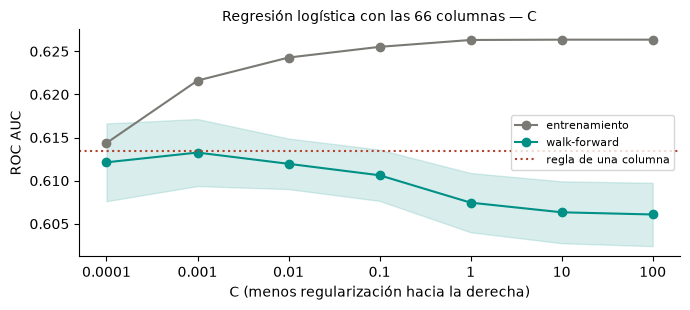

,0.0001,0.001,0.01,0.1,1,10,100
train,0.6144,0.6216,0.6243,0.6255,0.6263,0.6263,0.6264
validación,0.6121,0.6133,0.6120,0.6106,0.6074,0.6063,0.6061
desvío,0.0045,0.0039,0.0029,0.0030,0.0034,0.0036,0.0037


In [20]:
# La curva de validación de C para la logística con las 66 columnas: cuánto hay que frenarla
from sklearn.model_selection import validation_curve

valores_C = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
tr, va = validation_curve(armar(LogisticRegression(max_iter=5000)), X_train, y_train, groups=g_train,
                          param_name="modelo__C", param_range=valores_C, cv=cv, scoring="roc_auc", n_jobs=-1)
etiquetas = [str(v) for v in valores_C]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(etiquetas, tr.mean(axis=1), marker="o", color=GRIS, label="entrenamiento")
ax.plot(etiquetas, va.mean(axis=1), marker="o", color=VERDE_AZUL, label="walk-forward")
ax.fill_between(etiquetas, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), color=VERDE_AZUL, alpha=0.15)
ax.axhline(comparacion.loc["regla: una columna", "AUC"], color=TERRACOTA, ls=":", label="regla de una columna")
ax.set_xlabel("C (menos regularización hacia la derecha)"); ax.set_ylabel("ROC AUC"); ax.legend(fontsize=8)
ax.set_title("Regresión logística con las 66 columnas — C", fontsize=10)
plt.tight_layout()
plt.show()
pd.DataFrame({"train": tr.mean(axis=1), "validación": va.mean(axis=1), "desvío": va.std(axis=1)}, index=etiquetas).T.round(4)

### 5.2 La elección

La regla, escrita antes de mirar el resultado:

1. **Entre familias**: un modelo más complejo que la logística se elige sólo si le gana a la mejor logística **por más que el desvío** de ésta.
2. **Dentro de la logística**: de todas las combinaciones que quedan a menos de un desvío de la mejor, se elige **la que usa menos columnas** (y ante empate, la más regularizada). Una diferencia menor que el desvío no es una diferencia, y una columna que no se puede justificar es una columna que hay que explicar sin motivo.

In [21]:
lr = busquedas["regresión logística"]
r = pd.DataFrame(lr.cv_results_)
r["n_columnas"] = r["param_elegir__bloques"].map(lambda b: sum(len(BLOQUES[x]) for x in b))
mejor_lr = r.loc[lr.best_index_]
dentro = r[r["mean_test_auc"] >= mejor_lr["mean_test_auc"] - mejor_lr["std_test_auc"]]
elegida = dentro.sort_values(["n_columnas", "param_modelo__C"]).iloc[0]

otra = max((n for n in busquedas if n != "regresión logística"), key=lambda n: busquedas[n].best_score_)
ventaja_otra = busquedas[otra].best_score_ - mejor_lr["mean_test_auc"]
gana_complejo = ventaja_otra > mejor_lr["std_test_auc"]

if gana_complejo:
    NOMBRE_FINAL = otra
    modelo_final = clone(busquedas[otra].best_estimator_)
    auc_cv_final = busquedas[otra].best_score_
    desvio_cv_final = busquedas[otra].cv_results_["std_test_auc"][busquedas[otra].best_index_]
else:
    NOMBRE_FINAL = "regresión logística"
    modelo_final = clone(lr.estimator).set_params(**elegida["params"])
    auc_cv_final, desvio_cv_final = elegida["mean_test_auc"], elegida["std_test_auc"]

pd.Series({"mejor otra familia": otra, "le saca a la mejor logística": round(ventaja_otra, 4),
           "desvío de la mejor logística": round(mejor_lr["std_test_auc"], 4), "¿gana el complejo?": gana_complejo,
           "modelo elegido": NOMBRE_FINAL,
           "columnas": legible(modelo_final.get_params()["elegir__bloques"]),
           "AUC en validación": round(auc_cv_final, 4), "desvío": round(desvio_cv_final, 4)})

mejor otra familia                    random forest
le saca a la mejor logística                -0.0027
desvío de la mejor logística                 0.0024
¿gana el complejo?                            False
modelo elegido                  regresión logística
columnas                                una columna
AUC en validación                            0.6135
desvío                                       0.0019
dtype: object

In [22]:
leer(f'''**Elegido: {NOMBRE_FINAL}, con {legible(modelo_final.get_params()['elegir__bloques'])}.** La mejor familia que no es la logística (`{otra}`) le {'gana' if ventaja_otra > 0 else 'pierde'} a la mejor logística por {c(abs(ventaja_otra), 4)} de AUC, {'más' if gana_complejo else 'menos'} que el desvío ({c(mejor_lr['std_test_auc'], 4)}): {'el complejo se justifica' if gana_complejo else 'el complejo no se justifica y se queda el simple'}. Dentro de la logística, {len(dentro)} de las {len(r)} combinaciones de la grilla quedan a menos de un desvío de la mejor: casi toda la tabla es un empate, y entre los empatados se elige el que usa menos columnas.''')

**Elegido: regresión logística, con una columna.** La mejor familia que no es la logística (`random forest`) le pierde a la mejor logística por 0,0027 de AUC, menos que el desvío (0,0024): el complejo no se justifica y se queda el simple. Dentro de la logística, 12 de las 20 combinaciones de la grilla quedan a menos de un desvío de la mejor: casi toda la tabla es un empate, y entre los empatados se elige el que usa menos columnas.

### 5.3 El desbalance: una decisión con su número

No hay desbalance que corregir: A gana alrededor del 50 % de las veces en entrenamiento y en test, y no puede ser de otra forma porque A es una etiqueta arbitraria. La decisión es **no hacer nada**: ni `class_weight`, ni mover el umbral, que queda en 0,5 porque el problema es simétrico. Para que sea una decisión medida y no una omisión, el mismo modelo con `class_weight="balanced"`:

In [23]:
balanceado = medir(clone(modelo_final).set_params(modelo__class_weight="balanced"))
pd.Series({"proporción en que gana A (train)": y_train.mean(), "proporción en que gana A (test)": y_test.mean(),
           "AUC sin balancear": auc_cv_final, "AUC con class_weight='balanced'": balanceado["AUC"],
           "accuracy con class_weight='balanced'": balanceado["accuracy"]}).round(4)

proporción en que gana A (train)        0.5068
proporción en que gana A (test)         0.5021
AUC sin balancear                       0.6135
AUC con class_weight='balanced'         0.6135
accuracy con class_weight='balanced'    0.5799
dtype: float64

## 6. Las columnas que probamos y no sirvieron

Partiendo de la logística con las 66 columnas (con el `C` que mejor le fue en la grilla), se mide qué pasa al **sacar** cada bloque, y partiendo de la regla de una columna, qué pasa al **agregar** cada uno. Un bloque que no mueve el AUC más que el desvío no aporta, aunque en la Entrega 2 haya tenido una separación marginal decente: puede estar diciendo lo mismo que otro.

In [24]:
# el C con el que mejor le fue a la logística con las 66 columnas en la grilla de la sección 5
C_ref = r[r["param_elegir__bloques"] == TODAS].sort_values("mean_test_auc").iloc[-1]["param_modelo__C"]

def auc_de(bloques):
    return medir(armar(LogisticRegression(max_iter=5000, C=C_ref), bloques))

con_todas = auc_de(TODAS)
regla_sola = auc_de(("fuerza_media",))
filas = []
for b in TODAS + ("rango",):
    sin = auc_de(tuple(x for x in TODAS if x != b)) if b in TODAS else None
    con = auc_de(TODAS + (b,)) if b == "rango" else None
    sumado = auc_de(("fuerza_media", b)) if b != "fuerza_media" else regla_sola
    filas.append({"bloque": b, "columnas": len(BLOQUES[b]),
                  "Δ AUC al sacarlo de las 66": (sin["AUC"] - con_todas["AUC"]) if sin else np.nan,
                  "Δ AUC al sumarlo a las 66": (con["AUC"] - con_todas["AUC"]) if con else np.nan,
                  "Δ AUC al sumarlo a la regla": sumado["AUC"] - regla_sola["AUC"],
                  "desvío de referencia": con_todas["desvío AUC"]})
bloques_probados = pd.DataFrame(filas).set_index("bloque")
bloques_probados.round(4)

,columnas,Δ AUC al sacarlo de las 66,Δ AUC al sumarlo a las 66,Δ AUC al sumarlo a la regla,desvío de referencia
bloque,,,,,
fuerza_media,1,-0.0001,NaN,0.0000,0.0039
fuerza_resto,3,0.0001,NaN,-0.0029,0.0039
counter_winrate,4,-0.0000,NaN,-0.0011,0.0039
counter_otras,16,0.0002,NaN,-0.0035,0.0039
synergy,4,-0.0002,NaN,-0.0014,0.0039
composicion,38,-0.0023,NaN,0.0000,0.0039
rango,1,NaN,0.0003,0.0004,0.0039


In [25]:
aporta = bloques_probados["Δ AUC al sumarlo a la regla"].drop("fuerza_media")
utiles = aporta[aporta > bloques_probados["desvío de referencia"].iloc[0]]
leer(f'''Con las 66 columnas el AUC es {c(con_todas['AUC'])} y con una sola {c(regla_sola['AUC'])}. Sumado a la regla, ningún bloque suma más que {c(aporta.max(), 4)} de AUC{'' if len(utiles) else ', y ninguno supera el desvío'}{'; los que lo superan: ' + ', '.join(f'`{b}`' for b in utiles.index) if len(utiles) else ''}. La fuerza individual promedio ya contiene casi todo lo que dicen los cruces y las parejas: lo mismo que encontró H3 en la Entrega 2, ahora medido con un modelo en vez de con una correlación.

`average_badge_diff` (bloque `rango`), que la Entrega 2 dejó abierta: sumado a las 66 columnas mueve el AUC {c(bloques_probados.loc['rango', 'Δ AUC al sumarlo a las 66'], 4)}. Sale, como se decidió en H4.''')

Con las 66 columnas el AUC es 0,613 y con una sola 0,613. Sumado a la regla, ningún bloque suma más que 0,0004 de AUC, y ninguno supera el desvío. La fuerza individual promedio ya contiene casi todo lo que dicen los cruces y las parejas: lo mismo que encontró H3 en la Entrega 2, ahora medido con un modelo en vez de con una correlación.

`average_badge_diff` (bloque `rango`), que la Entrega 2 dejó abierta: sumado a las 66 columnas mueve el AUC 0,0003. Sale, como se decidió en H4.

### 6.1 Bloques acumulados y todos menos uno

La tabla de arriba mueve los bloques de a uno contra dos referencias fijas. Acá las columnas se juntan en cuatro bloques más gruesos, por lo que dicen, y se miden de dos formas con la misma logística (el `C` de arriba) y el mismo walk-forward:

- **Acumulando**: el bloque 1 solo, después 1 + 2, después 1 + 2 + 3, y así hasta tener todo. Mide cuánto suma cada bloque *encima* de los anteriores.
- **Todos menos uno**: todos los bloques salvo el 1, todos salvo el 2, etc. Mide cuánto se pierde al sacar cada bloque *cuando están los demás*: si no se pierde nada, lo que dice ese bloque ya lo dice otro.

| Bloque | Qué tiene | Columnas |
|---|---|---|
| 1. `winrates` | la media de las tres ventajas de winrate: la individual (`hero_`), la de los cruces (`counter_`) y la de las parejas (`synergy_`) | 3 |
| 2. `counter_synergy` | el resto de counter y synergy: mínimo, máximo y desvío de sus winrates, y las de kills, muertes, asistencias y souls | 22 |
| 3. `fuerza` | la fuerza individual entera: `fuerza_media` + `fuerza_resto` | 4 |
| 4. `composicion` | un héroe por columna | 38 |

`hero_winrate_adv_mean` está en el bloque 1 y en el 3 a propósito, porque el 3 es la fuerza individual completa. Los bloques se juntan como conjuntos de columnas, así que nunca entra dos veces, y "todos menos el 3" la conserva porque sigue estando en el 1. Los cuatro juntos son las 66 columnas.


In [26]:
BLOQUES.update({
    "winrates":        ["hero_winrate_adv_mean", "counter_winrate_adv_mean", "synergy_winrate_adv_mean"],
    "counter_synergy": [k for k in schema.COUNTER + schema.SYNERGY if k not in ("counter_winrate_adv_mean", "synergy_winrate_adv_mean")],
    "fuerza":          BLOQUES["fuerza_media"] + BLOQUES["fuerza_resto"],
})
ORDEN = ("winrates", "counter_synergy", "fuerza", "composicion")
assert set().union(*(BLOQUES[b] for b in ORDEN)) == set(schema.FEATURE_COLUMNS)


def medir_bloques(bloques):
    m = auc_de(bloques)
    return {"columnas": len(set().union(*(BLOQUES[b] for b in bloques))), "AUC": m["AUC"], "desvío AUC": m["desvío AUC"],
            "accuracy": m["accuracy"], "desvío acc": m["desvío acc"]}


numeros = lambda bloques: " + ".join(str(ORDEN.index(b) + 1) for b in bloques)
acumulados = pd.DataFrame({numeros(ORDEN[:k]): {"se suma": ORDEN[k - 1], **medir_bloques(ORDEN[:k])}
                           for k in range(1, len(ORDEN) + 1)}).T.infer_objects()
acumulados["Δ AUC vs. el anterior"] = acumulados["AUC"].astype(float).diff()
con_los_cuatro = acumulados["AUC"].iloc[-1]
menos_uno = pd.DataFrame({f"todos menos {i + 1}": {"se saca": b, **medir_bloques(tuple(x for x in ORDEN if x != b))}
                          for i, b in enumerate(ORDEN)}).T.infer_objects()
menos_uno["Δ AUC vs. los cuatro"] = menos_uno["AUC"].astype(float) - con_los_cuatro

display(Markdown("**Acumulando bloques**"), acumulados.round(4))
display(Markdown("**Todos los bloques menos uno**"), menos_uno.round(4))


**Acumulando bloques**

,se suma,columnas,AUC,desvío AUC,accuracy,desvío acc,Δ AUC vs. el anterior
1,winrates,3,0.6139,0.0019,0.5817,0.0011,NaN
1 + 2,counter_synergy,25,0.6111,0.0048,0.5804,0.0021,-0.0028
1 + 2 + 3,fuerza,28,0.6110,0.0049,0.5801,0.0018,-0.0001
1 + 2 + 3 + 4,composicion,66,0.6133,0.0039,0.5814,0.0042,0.0023


**Todos los bloques menos uno**

,se saca,columnas,AUC,desvío AUC,accuracy,desvío acc,Δ AUC vs. los cuatro
todos menos 1,winrates,64,0.6125,0.0042,0.5802,0.0042,-0.0008
todos menos 2,counter_synergy,44,0.6139,0.0031,0.5813,0.0042,0.0007
todos menos 3,fuerza,63,0.6134,0.0038,0.5827,0.0040,0.0001
todos menos 4,composicion,28,0.6110,0.0049,0.5801,0.0018,-0.0023


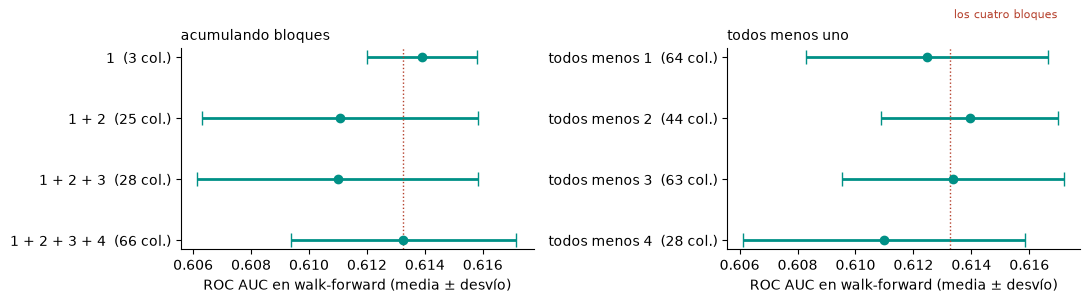

In [27]:
# Las dos tablas, dibujadas: el punto es la media del AUC en los pasos y la barra, un desvío a cada lado
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
for ax, tabla, titulo in [(axes[0], acumulados, "acumulando bloques"), (axes[1], menos_uno, "todos menos uno")]:
    etiquetas = [f"{i}  ({n} col.)" for i, n in zip(tabla.index, tabla["columnas"])]
    ax.errorbar(tabla["AUC"].astype(float), etiquetas, xerr=tabla["desvío AUC"].astype(float), fmt="o",
                color=VERDE_AZUL, ecolor=VERDE_AZUL, elinewidth=2, capsize=5)
    ax.axvline(con_los_cuatro, color=TERRACOTA, ls=":", lw=1)
    ax.invert_yaxis()
    ax.set_title(titulo, fontsize=10, loc="left")
    ax.set_xlabel("ROC AUC en walk-forward (media ± desvío)")
axes[1].text(con_los_cuatro, -0.6, " los cuatro bloques", color=TERRACOTA, fontsize=8, va="bottom")
plt.tight_layout()
plt.show()


In [28]:
desvio_61 = acumulados["desvío AUC"].astype(float).iloc[-1]
suma = acumulados["Δ AUC vs. el anterior"].iloc[1:].astype(float)
pierde = menos_uno["Δ AUC vs. los cuatro"].astype(float)
bloque_que_suma = acumulados.loc[suma.idxmax(), "se suma"]
bloque_que_duele = menos_uno.loc[pierde.idxmin(), "se saca"]
nadie_duele = pierde.min() > -desvio_61
leer(f'''**Acumulando.** El bloque 1 solo (`winrates`, 3 columnas) da AUC **{c(acumulados['AUC'].iloc[0])}**, y con los cuatro bloques (66 columnas) **{c(con_los_cuatro)}** (± {c(desvio_61)}). El bloque que más suma encima de los anteriores es `{bloque_que_suma}`, con {c(suma.max(), 4)} de AUC{', menos que el desvío: ningún escalón es una diferencia' if suma.max() < desvio_61 else ''}{'; el que más resta es `' + acumulados.loc[suma.idxmin(), 'se suma'] + '`, ' + c(suma.min(), 4) if suma.min() < 0 else ''}.

**Todos menos uno.** Sacar `{bloque_que_duele}` es lo que más cambia el AUC ({c(pierde.min(), 4)}){': aun así queda dentro del desvío, así que con los otros tres bloques ninguno es imprescindible — lo que dice cada uno ya está en otro' if nadie_duele else ', más que el desvío: es el bloque cuya información no está en ningún otro'}. {'Sacar `composicion` sube el AUC ' + c(pierde['todos menos 4'], 4) + ': los pesos por héroe aprendidos en un corte empeoran la predicción del siguiente.' if pierde['todos menos 4'] > 0 else ''}''')


**Acumulando.** El bloque 1 solo (`winrates`, 3 columnas) da AUC **0,614**, y con los cuatro bloques (66 columnas) **0,613** (± 0,004). El bloque que más suma encima de los anteriores es `composicion`, con 0,0023 de AUC, menos que el desvío: ningún escalón es una diferencia; el que más resta es `counter_synergy`, -0,0028.

**Todos menos uno.** Sacar `composicion` es lo que más cambia el AUC (-0,0023): aun así queda dentro del desvío, así que con los otros tres bloques ninguno es imprescindible — lo que dice cada uno ya está en otro. 

### 6.2 Lo que se probó fuera del pipeline

Antes de este notebook se exploraron tres fuentes de señal que el DAG todavía no baja, sobre dos cortes armados a mano con las mismas funciones del pipeline (20/08 y 05/09, 10.000 partidas cada uno; validación entrenando en uno y midiendo en el otro). Ninguna se incorporó:

| Qué se probó | Por qué podía servir | Accuracy entre cortes | Veredicto |
|---|---|---|---|
| Regla de una columna (referencia) | — | 0,580 | — |
| Counters y sinergias **de carril** (`same_lane_filter`, 3 carriles × 2 héroes) | los enfrentamientos reales de la fase de carriles, no el promedio de los 36 cruces | 0,585 | no aporta: correlaciona 0,99 con la fuerza individual |
| Fuerza de cada héroe **por tramo de rango** (`min/max_average_badge`) | un héroe puede ser fuerte en rangos bajos y no en altos | 0,583 | no aporta: correlaciona 0,96 |
| Datos de **jugadores** previos a la partida (racha, progreso, calibración) | lo que la composición no ve | 0,594 | +1 punto, pero no es composición: responde otra pregunta |
| `k` del shrinkage | menos ruido en las ventajas | — | no puede aportar: cada héroe tiene 100.000–300.000 partidas en la ventana y cada pareja 15.000–27.000 |

*Estos números no salen de este notebook; los scripts quedan como evidencia del grupo.*

## 7. El modelo final, leído

Todo lo anterior se eligió con el walk-forward sobre el entrenamiento. Recién ahora se da el paso final de la ventana deslizante: el modelo elegido se entrena **con los últimos `m` cortes de entrenamiento** (con `m = 1`, sólo el más reciente) y se mira el test, **una vez**. Al lado, el piso y la regla de una columna, entrenados igual: son referencias, no candidatos.


In [29]:
from sklearn.metrics import roc_auc_score, accuracy_score

ultimos = sorted(g_train.unique())[-VENTANA:]   # el paso final de la ventana deslizante
X_final, y_final = X_train[g_train.isin(ultimos)], y_train[g_train.isin(ultimos)]
modelo_final.fit(X_final, y_final)
p_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (p_test >= 0.5).astype(int)

referencias = {n: clone(modelos[n]).fit(X_final, y_final) for n in ["piso (dummy)", "regla: una columna"]}
resultado = pd.DataFrame({
    **{n: {"AUC en test": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]),
           "accuracy en test": accuracy_score(y_test, m.predict(X_test))} for n, m in referencias.items()},
    f"elegido: {NOMBRE_FINAL}": {"AUC en test": roc_auc_score(y_test, p_test), "accuracy en test": accuracy_score(y_test, pred_test),
                                 "AUC en validación": auc_cv_final},
}).T
resultado.round(4)

,AUC en test,accuracy en test,AUC en validación
piso (dummy),0.5000,0.5021,NaN
regla: una columna,0.6075,0.5744,NaN
elegido: regresión logística,0.6075,0.5747,0.6135


In [30]:
auc_t, acc_t = roc_auc_score(y_test, p_test), accuracy_score(y_test, pred_test)
acc_piso = resultado.iloc[0]["accuracy en test"]
leer(f'''Entrenado con `{', '.join(ultimos)}` ({miles(len(X_final))} partidas). En el corte `{CORTE_TEST}`, que el modelo no vio, el AUC es **{c(auc_t)}** y la accuracy **{c(acc_t)}**: acierta {acc_t:.1%} de las partidas contra {acc_piso:.1%} del piso, **{(acc_t - acc_piso) * 100:.1f} puntos más**. En validación había dado {c(auc_cv_final)} ± {c(desvio_cv_final)}; {'el test queda dentro de esa banda, que es lo que tiene que pasar cuando la elección fue honesta' if abs(auc_t - auc_cv_final) <= 2 * max(desvio_cv_final, 0.005) else 'el test se aparta de esa banda, y eso hay que explicarlo: el corte de test es de otro momento del juego'}.

**¿Es mucho o poco?** Para predecir el resultado de una partida concreta, poco: cuatro de cada diez se erran. Para la pregunta del proyecto —*¿se puede saber quién gana sabiendo sólo la composición?*— es la respuesta: **en parte, y no mucho más que esto**. La composición mueve la balanza unos puntos; el resto lo deciden las doce personas que juegan, y el matchmaking ya iguala sus rangos (H4). Un modelo de composición que diera 70 % sería sospechoso de fuga antes que motivo de festejo.''')

Entrenado con `2026-09-10` (10.000 partidas). En el corte `2026-09-20`, que el modelo no vio, el AUC es **0,608** y la accuracy **0,575**: acierta 57,5% de las partidas contra 50,2% del piso, **7,3 puntos más**. En validación había dado 0,613 ± 0,002; el test queda dentro de esa banda, que es lo que tiene que pasar cuando la elección fue honesta.

**¿Es mucho o poco?** Para predecir el resultado de una partida concreta, poco: cuatro de cada diez se erran. Para la pregunta del proyecto —*¿se puede saber quién gana sabiendo sólo la composición?*— es la respuesta: **en parte, y no mucho más que esto**. La composición mueve la balanza unos puntos; el resto lo deciden las doce personas que juegan, y el matchmaking ya iguala sus rangos (H4). Un modelo de composición que diera 70 % sería sospechoso de fuga antes que motivo de festejo.

### 7.1 Dónde se equivoca

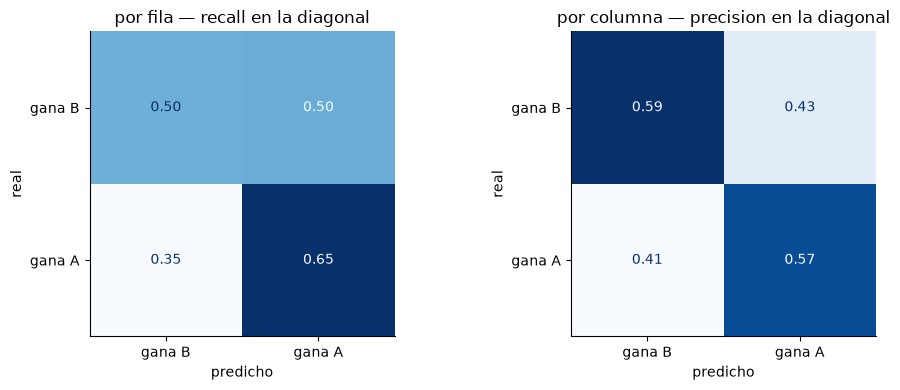

,precision,recall,f1-score,support
gana B,0.586,0.498,0.538,4979.000
gana A,0.567,0.651,0.606,5021.000
accuracy,0.575,0.575,0.575,0.575
macro avg,0.576,0.574,0.572,10000.000
weighted avg,0.576,0.575,0.572,10000.000


In [31]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

nombres = ["gana B", "gana A"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, normalizar, titulo in [(axes[0], "true", "por fila — recall en la diagonal"), (axes[1], "pred", "por columna — precision en la diagonal")]:
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, ax=ax, cmap="Blues", colorbar=False, normalize=normalizar,
                                            values_format=".2f", display_labels=nombres)
    ax.set_title(titulo); ax.set_xlabel("predicho"); ax.set_ylabel("real")
plt.tight_layout()
plt.show()
pd.DataFrame(classification_report(y_test, pred_test, target_names=nombres, output_dict=True)).T.round(3)

Las dos matrices son casi simétricas, y tienen que serlo: el modelo no tiene preferencia por un lado, así que se equivoca igual para A que para B. La confusión no está en una clase sino en **qué tan clara era la partida**. Eso se lee mejor por tramo de confianza y por nivel de juego.

In [32]:
analisis = df.loc[es_test, ["match_id", "average_badge", "hero_winrate_adv_mean"]].assign(
    real=y_test.values, prob=p_test, pred=pred_test)
analisis["acierto"] = analisis["real"].eq(analisis["pred"])
analisis["confianza"] = (analisis["prob"] - 0.5).abs()

def por_grupo(columna):
    filas = {}
    for grupo, t in analisis.groupby(columna, observed=True):
        filas[grupo] = {"partidas": len(t), "accuracy": t["acierto"].mean(), "AUC": roc_auc_score(t["real"], t["prob"])}
    return pd.DataFrame(filas).T

analisis["tramo de confianza"] = pd.qcut(analisis["confianza"], 5, labels=["20 % menos seguras", "2.º quintil", "3.º quintil", "4.º quintil", "20 % más seguras"])
analisis["tramo de badge"] = pd.cut(analisis["average_badge"], [0, 40, 60, 80, 200], labels=["≤40", "41-60", "61-80", ">80"])
pd.concat({"por confianza": por_grupo("tramo de confianza"), "por nivel de juego": por_grupo("tramo de badge")}).round(3)

partidas  accuracy    AUC
por confianza      20 % menos seguras    2000.0     0.511  0.520
                   2.º quintil           2000.0     0.532  0.546
                   3.º quintil           2000.0     0.572  0.578
                   4.º quintil           2000.0     0.594  0.596
                   20 % más seguras      2000.0     0.663  0.680
por nivel de juego ≤40                   3376.0     0.574  0.611
                   41-60                 2100.0     0.573  0.609
                   61-80                 1976.0     0.587  0.611
                   >80                   2548.0     0.567  0.599

In [33]:
conf = por_grupo("tramo de confianza"); badge = por_grupo("tramo de badge")
leer(f'''**Por confianza.** En el 20 % de partidas donde el modelo está más seguro acierta el **{conf['accuracy'].iloc[-1]:.1%}**; en el 20 % donde está menos seguro, el {conf['accuracy'].iloc[0]:.1%}, prácticamente una moneda. El modelo sabe cuándo no sabe: la mayoría de las partidas tienen composiciones parejas, y ahí la composición no decide.

**Por nivel de juego.** La accuracy va de {badge['accuracy'].min():.1%} (`{badge['accuracy'].idxmin()}`) a {badge['accuracy'].max():.1%} (`{badge['accuracy'].idxmax()}`). La Entrega 2 encontró en H1 que la ventaja de composición separaba menos en el tramo más alto (`>80`); acá ese tramo da {badge.loc['>80', 'accuracy']:.1%}. Una hipótesis de dominio, no medida acá: las estadísticas de los 14 días están dominadas por partidas de nivel medio y bajo, y los jugadores de más nivel pueden sacarle rendimiento a héroes que en esas estadísticas aparecen como flojos.''')

**Por confianza.** En el 20 % de partidas donde el modelo está más seguro acierta el **66,3%**; en el 20 % donde está menos seguro, el 51,1%, prácticamente una moneda. El modelo sabe cuándo no sabe: la mayoría de las partidas tienen composiciones parejas, y ahí la composición no decide.

**Por nivel de juego.** La accuracy va de 56,7% (`>80`) a 58,7% (`61-80`). La Entrega 2 encontró en H1 que la ventaja de composición separaba menos en el tramo más alto (`>80`); acá ese tramo da 56,7%. Una hipótesis de dominio, no medida acá: las estadísticas de los 14 días están dominadas por partidas de nivel medio y bajo, y los jugadores de más nivel pueden sacarle rendimiento a héroes que en esas estadísticas aparecen como flojos.

In [34]:
# Una confusión concreta: las partidas donde el modelo estaba más seguro y se equivocó
heroes_de = lambda fila, signo: ", ".join(k.replace("hero_", "") for k in schema.COMPOSICION if fila[k] == signo)
peores = analisis[~analisis["acierto"]].nlargest(5, "confianza")
detalle = df.loc[peores.index]
pd.DataFrame({"prob. gana A": peores["prob"].round(3), "ganó": np.where(peores["real"] == 1, "A", "B"),
              "ventaja de fuerza": peores["hero_winrate_adv_mean"].round(3), "badge": peores["average_badge"],
              "héroes de A": detalle.apply(heroes_de, axis=1, signo=1), "héroes de B": detalle.apply(heroes_de, axis=1, signo=-1)})

,prob. gana A,ganó,ventaja de fuerza,badge,héroes de A,héroes de B
44044,0.719,B,0.099,46,"wraith, calico, drifter, victor, paige, apollo","lady_geist, holliday, lash, pocket, mirage, mina"
47115,0.716,B,0.097,13,"seven, warden, victor, paige, graves, apollo","shiv, ivy, sinclair, venator, billy, celeste"
42664,0.713,B,0.096,86,"wraith, haze, mo_and_krill, victor, apollo, rem","infernus, paradox, pocket, mina, venator, billy"
40232,0.712,B,0.095,15,"seven, lady_geist, viscous, victor, paige, celeste","bebop, yamato, pocket, venator, billy, rem"
44241,0.289,A,-0.108,75,"infernus, bebop, grey_talon, shiv, pocket, venator","seven, wraith, calico, mo_and_krill, yamato, paige"


En estos errores la ventaja de fuerza de los héroes estaba muy cargada para un lado, y ganó el otro. Es lo esperable en un juego donde la composición es una ventaja de punto de partida y no una sentencia: un equipo con héroes que estadísticamente ganan menos puede ganar igual si los juega mejor. No hay una columna que el modelo esté leyendo mal; hay una variable —quién juega— que no tiene.

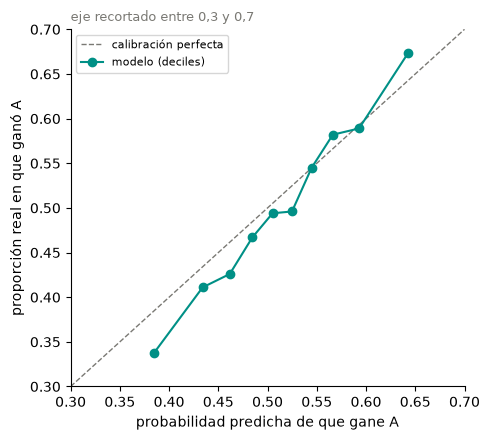

Las probabilidades del modelo van de 27% a 76%: nunca dice "seguro". Por deciles, la diferencia media entre lo que predice y lo que pasa es de 2,1 puntos, así que un "60 %" en la aplicación se puede leer como 60 %.

In [35]:
# La calibración: cuando dice 60 %, ¿gana A el 60 % de las veces? Es lo que va a mostrar la aplicación
from sklearn.calibration import calibration_curve

frac, media = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot([0.3, 0.7], [0.3, 0.7], ls="--", color=GRIS, lw=1, label="calibración perfecta")
ax.plot(media, frac, marker="o", color=VERDE_AZUL, label="modelo (deciles)")
ax.set_xlabel("probabilidad predicha de que gane A"); ax.set_ylabel("proporción real en que ganó A")
ax.set_title("eje recortado entre 0,3 y 0,7", fontsize=9, color=GRIS, loc="left"); ax.legend(fontsize=8)
ax.set_xlim(0.3, 0.7); ax.set_ylim(0.3, 0.7)
plt.tight_layout()
plt.show()
leer(f'''Las probabilidades del modelo van de {p_test.min():.0%} a {p_test.max():.0%}: nunca dice "seguro". Por deciles, la diferencia media entre lo que predice y lo que pasa es de {np.abs(frac - media).mean() * 100:.1f} puntos, así que un "60 %" en la aplicación se puede leer como 60 %.''')

### 7.2 En qué se apoya

In [36]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(modelo_final, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEMILLA, n_jobs=-1)
importancia = pd.DataFrame({"caída de AUC al desordenarla": pi.importances_mean, "desvío": pi.importances_std}, index=X_test.columns)
importancia = importancia[importancia["caída de AUC al desordenarla"].abs() > 0].sort_values("caída de AUC al desordenarla", ascending=False)
importancia.head(10).round(4)

,caída de AUC al desordenarla,desvío
hero_winrate_adv_mean,0.1111,0.0052


In [37]:
if NOMBRE_FINAL == "regresión logística":
    lineal = modelo_final["modelo"]
    pesos = pd.Series(lineal.coef_[0], index=modelo_final["elegir"].columnas_)
    display(pd.DataFrame({"peso (columna estandarizada)": pesos, "intercepto": lineal.intercept_[0]}).round(4))
top = importancia.index[0]
leer(f'''La columna que más pesa es `{top}`: desordenarla en el test baja el AUC {c(importancia.iloc[0, 0], 4)}. {'Su peso es positivo: cuanto más fuertes son, en promedio, los héroes de A respecto de los de B según los 14 días anteriores, más probabilidad le da a A.' if top == 'hero_winrate_adv_mean' else ''}

**Por qué no es una fuga.** (1) Se calcula con partidas **anteriores** al corte, y la sección 1 verificó que ninguna partida del dataset cae en esa ventana. (2) Si contuviera la respuesta, el AUC estaría cerca de 1, no en {c(auc_t)}. (3) La comparación entre partir por corte y al azar (sección 4) muestra que su rendimiento casi no cambia entre partir por corte o al azar: no depende de ver el mismo momento del juego de los dos lados. (4) Existe antes de jugar: la composición se conoce al terminar la selección de héroes.''')

,peso (columna estandarizada),intercepto
hero_winrate_adv_mean,0.2987,0.0626


La columna que más pesa es `hero_winrate_adv_mean`: desordenarla en el test baja el AUC 0,1111. Su peso es positivo: cuanto más fuertes son, en promedio, los héroes de A respecto de los de B según los 14 días anteriores, más probabilidad le da a A.

**Por qué no es una fuga.** (1) Se calcula con partidas **anteriores** al corte, y la sección 1 verificó que ninguna partida del dataset cae en esa ventana. (2) Si contuviera la respuesta, el AUC estaría cerca de 1, no en 0,608. (3) La comparación entre partir por corte y al azar (sección 4) muestra que su rendimiento casi no cambia entre partir por corte o al azar: no depende de ver el mismo momento del juego de los dos lados. (4) Existe antes de jugar: la composición se conoce al terminar la selección de héroes.

Como contexto —no es el modelo elegido—, qué aprende una logística que ve a los 38 héroes por separado: el peso de cada héroe cuando juega en A. Es la lectura de "qué héroes empujan", aunque en la sección 6 se vio que estos pesos no suman nada a la fuerza individual promedio.

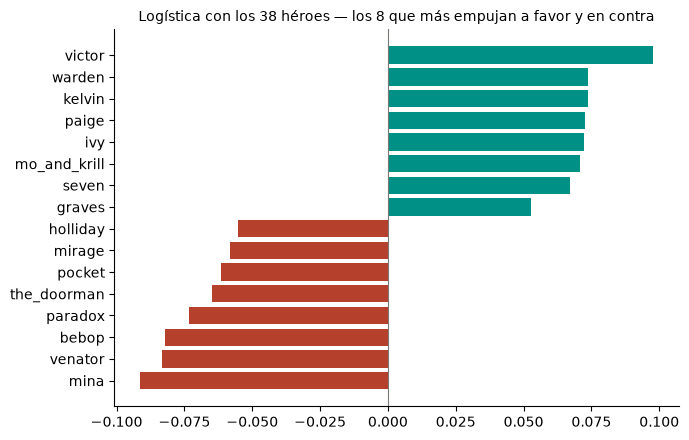

In [38]:
con_heroes = armar(LogisticRegression(max_iter=5000, C=C_ref), ("composicion",)).fit(X_final, y_final)
pesos_heroes = pd.Series(con_heroes["modelo"].coef_[0], index=[k.replace("hero_", "") for k in schema.COMPOSICION]).sort_values()
extremos = pd.concat([pesos_heroes.head(8), pesos_heroes.tail(8)])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(extremos.index, extremos.values, color=np.where(extremos.values > 0, VERDE_AZUL, TERRACOTA))
ax.axvline(0, color=GRIS, lw=0.8)
ax.set_title("Logística con los 38 héroes — los 8 que más empujan a favor y en contra", fontsize=10)
plt.tight_layout()
plt.show()

## 8. El modelo que se lleva la Entrega 4

In [39]:
import joblib

DESTINO = RAIZ / "notebooks" / "modelo_entrega3.joblib"
joblib.dump({"modelo": modelo_final, "columnas": COLUMNAS, "cortes_entrenamiento": ultimos, "corte_test": CORTE_TEST, "semilla": SEMILLA}, DESTINO)
print("guardado:", DESTINO.relative_to(RAIZ))

guardado: notebooks\modelo_entrega3.joblib


Un aviso para la aplicación: entre el 21/09 y el 19/10 Valve agregó **cinco héroes nuevos** (ids 78, 84, 85, 86 y 88), y el catálogo del pipeline tiene 38. Un modelo que aprendiera un peso por héroe no podría predecir una partida con un héroe que no vio. Un modelo que se apoya en la fuerza individual calculada con las estadísticas recientes sí puede, siempre que el pipeline baje las estadísticas de los héroes nuevos.

In [40]:
leer(f'''## Cierre

- **Qué se predice:** si gana el equipo A, con ROC AUC como métrica y accuracy al lado.
- **Contra qué:** el piso es {c(comparacion.loc['piso (dummy)', 'accuracy'])} de accuracy; la regla de una columna, {c(comparacion.loc['regla: una columna', 'accuracy'])} en validación.
- **Cómo se partió:** walk-forward con ventana deslizante de {VENTANA} corte, porque el modelo se usa sobre un momento del juego que no vio; el final se entrenó con `{', '.join(ultimos)}` y el test es el corte `{CORTE_TEST}`.
- **Qué se eligió:** {NOMBRE_FINAL} con {legible(modelo_final.get_params()['elegir__bloques'])}. Ningún modelo más complejo le ganó por más que el desvío.
- **Cuánto da:** AUC {c(auc_t)} y accuracy {c(acc_t)} en el test.
- **Qué no anduvo:** las otras 65 columnas, los modelos de árboles, `average_badge_diff`, los counters de carril y la fuerza por tramo de rango.''')

## Cierre

- **Qué se predice:** si gana el equipo A, con ROC AUC como métrica y accuracy al lado.
- **Contra qué:** el piso es 0,501 de accuracy; la regla de una columna, 0,580 en validación.
- **Cómo se partió:** walk-forward con ventana deslizante de 1 corte, porque el modelo se usa sobre un momento del juego que no vio; el final se entrenó con `2026-09-10` y el test es el corte `2026-09-20`.
- **Qué se eligió:** regresión logística con una columna. Ningún modelo más complejo le ganó por más que el desvío.
- **Cuánto da:** AUC 0,608 y accuracy 0,575 en el test.
- **Qué no anduvo:** las otras 65 columnas, los modelos de árboles, `average_badge_diff`, los counters de carril y la fuerza por tramo de rango.